# 2048 — Part 1: exact Dynamic Programming

Project work for *Dynamic Programming and Reinforcement Learning*.

This notebook solves small versions of 2048 exactly and studies the optimal policy. The problem formulation (state, controls, disturbance, Bellman equation and the structural properties used here) is in `formulation/2048_formulation.pdf`.

Files in this folder:
- `game2048.py`: rules of the game, shared with the RL part, including a Gymnasium-style environment;
- `dp2048.py`: exact DP (reachable states by stage, backward recursion, policy evaluation, Monte Carlo simulation);
- `test_2048.py`: checks of the engine and of the DP (`python test_2048.py`).

Requirements: Python 3 with `numpy` and `matplotlib`, run from this folder (on Colab, upload the two `.py` files first).

In [1]:
import time

import matplotlib.pyplot as plt
import numpy as np

import dp2048 as dp
from game2048 import Env2048, Game2048

plt.rcParams['figure.figsize'] = (7, 4)

## 1. The game engine

A board is a tuple of exponents in row-major order (0 = empty cell, $k$ = tile $2^k$). A move is split into the deterministic slide/merge, which gives the *afterstate*, and the random spawn of a 2 (probability $1-p_4$) or a 4 (probability $p_4$) in a uniformly chosen empty cell.

In [2]:
game = Game2048(rows=2, cols=3, target=64)
board = (1, 1, 0,
         0, 2, 2)
print(game.render(board), '\n')
for action, after, points in game.moves(board):
    print(f'{action:>5}: +{points:<3} afterstate {after}')

after, _ = game.afterstate(board, 'left')
print('\nnext states after "left":')
for nxt, p in game.spawn_distribution(after):
    print(f'  p = {p:.3f}  {nxt}')

2 2 .
. 4 4 

 down: +0   afterstate (0, 1, 0, 1, 2, 2)
 left: +12  afterstate (2, 0, 0, 3, 0, 0)
right: +12  afterstate (0, 0, 2, 0, 0, 3)
   up: +0   afterstate (1, 1, 2, 0, 2, 0)

next states after "left":
  p = 0.225  (2, 1, 0, 3, 0, 0)
  p = 0.025  (2, 2, 0, 3, 0, 0)
  p = 0.225  (2, 0, 1, 3, 0, 0)
  p = 0.025  (2, 0, 2, 3, 0, 0)
  p = 0.225  (2, 0, 0, 3, 1, 0)
  p = 0.025  (2, 0, 0, 3, 2, 0)
  p = 0.225  (2, 0, 0, 3, 0, 1)
  p = 0.025  (2, 0, 0, 3, 0, 2)


The slide/merge preserves the tile sum and the new tile adds 2 or 4, so the tile sum $\sigma$ strictly increases at every move (Proposition 1 of the formulation). The reachable states split into *stages* $X_\sigma$, and the DP is a single backward recursion over $\sigma$.

27,022 reachable decision states in 55 stages (0.29 s)


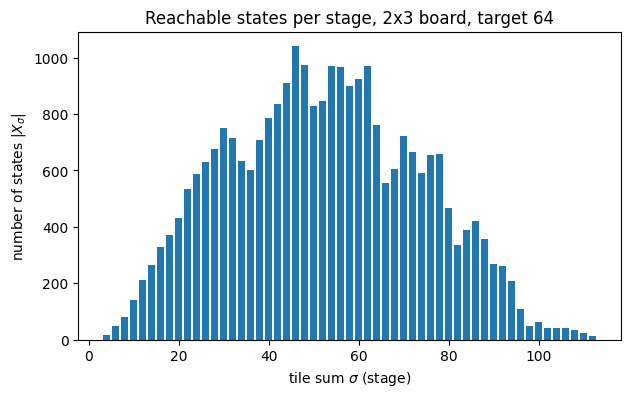

In [3]:
t0 = time.perf_counter()
layers = dp.reachable_layers(game)
print(f'{dp.count_states(layers):,} reachable decision states in {len(layers)} stages '
      f'({time.perf_counter() - t0:.2f} s)')

sigmas = sorted(layers)
plt.bar(sigmas, [len(layers[s]) for s in sigmas], width=1.6)
plt.xlabel(r'tile sum $\sigma$ (stage)')
plt.ylabel(r'number of states $|X_\sigma|$')
plt.title(f'Reachable states per stage, {game.rows}x{game.cols} board, target {game.target}')
plt.show()

## 2. Optimal policy by backward recursion

$V^*(x)$ is the maximum probability of creating the target tile from board $x$:

- $V^*(x) = 0$ if no move is legal (game over);
- $V^*(x) = \max_{u \in U(x)} W^*(M(x,u))$ otherwise, where $W^*(y) = 1$ if the afterstate $y$ contains the target tile and $W^*(y) = \mathbb{E}_w\left[V^*(S(y,w))\right]$ otherwise.

In [4]:
t0 = time.perf_counter()
V, table, layers = dp.solve_optimal(game, layers=layers)
p_opt = dp.start_value(game, V)
print(f'P(win) of the optimal policy: {p_opt:.4f} '
      f'(backward recursion in {time.perf_counter() - t0:.2f} s)')

P(win) of the optimal policy: 0.9393 (backward recursion in 0.18 s)


### Value iteration (total-cost formulation)

The course solves total-cost problems with termination states by value iteration (slides *11-Infinite-DP*). Here the win and the game over are absorbing, cost-free termination states that every policy reaches within $RC\,2^{K-2}$ moves (assumptions A2-A3), so no discount is needed. Starting from $V^{(0)}=0$, $V^{(i)}(x)$ is the probability of winning within $i$ moves: the iteration becomes exact after finitely many steps. Updating the states in place in decreasing tile sum (Gauss-Seidel), the first sweep already gives $V^*$: that is the backward recursion above.

value iteration: 47 iterations (8.7 s), exact from iteration 46, max |V_VI - V*| = 0.0e+00 (55 stages)


Gauss-Seidel in decreasing tile sum: 2 sweeps, error after the first sweep 0.0e+00


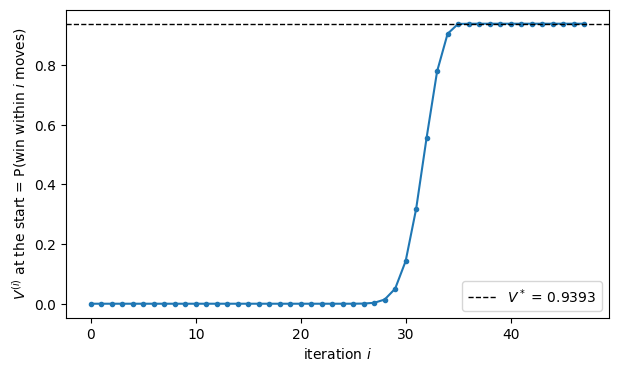

In [5]:
t0 = time.perf_counter()
V_vi, _, hist = dp.value_iteration(game, layers=layers, V_ref=V)
exact_from = next(h['iteration'] for h in hist if h['error'] == 0.0)
print(f'value iteration: {len(hist)} iterations ({time.perf_counter() - t0:.1f} s), exact from iteration '
      f'{exact_from}, max |V_VI - V*| = {max(abs(V_vi[b] - V[b]) for b in V):.1e} ({len(layers)} stages)')
_, _, hist_gs = dp.value_iteration(game, layers=layers, order='backward', V_ref=V)
print(f'Gauss-Seidel in decreasing tile sum: {len(hist_gs)} sweeps, '
      f'error after the first sweep {hist_gs[0]["error"]:.1e}')

fig, ax = plt.subplots()
ax.plot([0] + [h['iteration'] for h in hist], [0] + [h['start'] for h in hist], marker='o', ms=3)
ax.axhline(p_opt, ls='--', c='k', lw=1, label=f'$V^*$ = {p_opt:.4f}')
ax.set_xlabel('iteration $i$')
ax.set_ylabel('$V^{(i)}$ at the start = P(win within $i$ moves)')
ax.legend()
plt.show()

## 3. Benchmark policies (exact policy evaluation)

- **corner**: fixed priority down > left > right > up, the classic rule "keep the big tiles in a corner";
- **greedy**: the move with the largest immediate merge score;
- **random**: a uniformly random legal move.

Their values come from the same recursion, with the policy's choice in place of the maximisation.

In [6]:
values = {'optimal': p_opt}
for name, policy in dp.HEURISTICS.items():
    values[name] = dp.start_value(game, dp.evaluate_policy(game, policy, layers=layers))
for name, value in values.items():
    print(f'{name:>8}: P(win) = {value:.4f}')

 optimal: P(win) = 0.9393
  corner: P(win) = 0.0007
  greedy: P(win) = 0.0013
  random: P(win) = 0.0002


## 4. Monte Carlo check

Simulating the optimal policy must reproduce the exact value within the statistical error.

Monte Carlo: 0.9395 ± 0.0033 (95% CI), exact: 0.9393


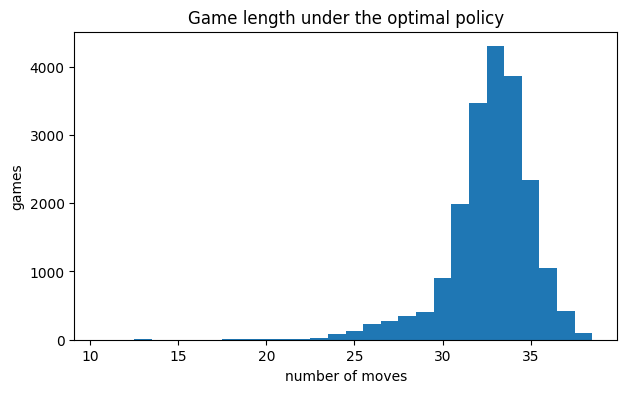

In [7]:
n_games = 20_000
results = dp.simulate(game, dp.table_policy(table), n_games, seed=42)
wins = np.array([r['won'] for r in results], dtype=float)
half_width = 1.96 * wins.std(ddof=1) / np.sqrt(n_games)
print(f'Monte Carlo: {wins.mean():.4f} ± {half_width:.4f} (95% CI), exact: {p_opt:.4f}')

moves = [r['moves'] for r in results]
plt.hist(moves, bins=np.arange(min(moves), max(moves) + 2) - 0.5)  # one bar per integer
plt.xlabel('number of moves')
plt.ylabel('games')
plt.title('Game length under the optimal policy')
plt.show()

## 5. Curse of dimensionality

Growth of the state space and of the DP time with the board. The 3x3 board has 4.8 million states: in pure Python its DP takes about 2 minutes, the whole comparison about 5, with roughly 1.5 GB of RAM. Set `RUN_BIG = True` to include it.

In [8]:
RUN_BIG = False
configs = [(2, 2, 16), (2, 2, 32), (2, 3, 32), (2, 3, 64), (2, 3, 128), (2, 4, 64)]
if RUN_BIG:
    configs.append((3, 3, 64))

rows = []
for r, c, target in configs:
    row = dp.compare_policies(Game2048(r, c, target=target))
    rows.append(row)
    print(f"{row['board']} target {row['target']:>3}: {row['states']:>9,} states, "
          f"DP {row['dp_time_s']:5.1f} s | P(win) optimal {row['optimal']:.4f}, "
          f"corner {row['corner']:.4f}, greedy {row['greedy']:.4f}, random {row['random']:.4f}")

2x2 target  16:       214 states, DP   0.0 s | P(win) optimal 0.9625, corner 0.2355, greedy 0.2474, random 0.1218
2x2 target  32:       422 states, DP   0.0 s | P(win) optimal 0.0829, corner 0.0000, greedy 0.0000, random 0.0005


2x3 target  32:    11,222 states, DP   0.2 s | P(win) optimal 0.9999, corner 0.2854, greedy 0.3365, random 0.0921


2x3 target  64:    27,022 states, DP   0.4 s | P(win) optimal 0.9393, corner 0.0007, greedy 0.0013, random 0.0002


2x3 target 128:    52,486 states, DP   0.8 s | P(win) optimal 0.0570, corner 0.0000, greedy 0.0000, random 0.0000


2x4 target  64:   881,260 states, DP  20.7 s | P(win) optimal 1.0000, corner 0.3611, greedy 0.3295, random 0.0274


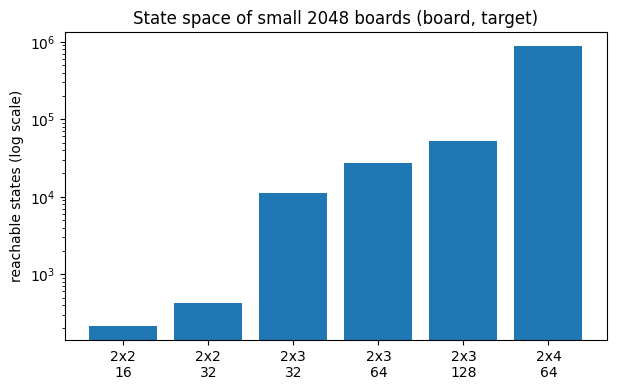

In [9]:
labels = [f"{row['board']}\n{row['target']}" for row in rows]
fig, ax = plt.subplots()
ax.bar(labels, [row['states'] for row in rows])
ax.set_yscale('log')
ax.set_ylabel('reachable states (log scale)')
ax.set_title('State space of small 2048 boards (board, target)')
plt.show()

## 6. When does the optimal policy break the corner rule?

Decisions are weighted by how often they occur when playing optimally (expected visits, from a forward pass over the stages). The *exceptions* are the boards where the corner move is strictly worse than the optimal one, ranked by visits × loss of win probability.

In [10]:
cmp = dp.compare_with_heuristic(game, V, table, layers, dp.corner_policy)
print(f"the corner move is optimal in {cmp['share']:.1%} of the decisions; "
      f"a game played optimally lasts {cmp['expected_moves']:.1f} moves on average")
for importance, board, corner_move, best_move, loss in cmp['exceptions'][:5]:
    print(f'\nimportance {importance:.4f}: the corner rule plays {corner_move}, '
          f'the optimal policy plays {best_move} (loss {loss:.3f})')
    print(game.render(board))

the corner move is optimal in 49.5% of the decisions; a game played optimally lasts 32.7 moves on average

importance 0.2363: the corner rule plays down, the optimal policy plays up (loss 0.900)
16  4  2
32  8  2

importance 0.0978: the corner rule plays left, the optimal policy plays right (loss 0.900)
32  2  2
16  8  4

importance 0.0965: the corner rule plays down, the optimal policy plays left (loss 0.858)
 8  8  4
32  .  2

importance 0.0855: the corner rule plays right, the optimal policy plays up (loss 0.900)
16  2  .
32  8  2

importance 0.0811: the corner rule plays left, the optimal policy plays right (loss 0.910)
 2 32  2
32  4  4


## 7. How much does luck matter?

Optimal win probability as a function of the probability $p_4$ that a new tile is a 4.

p4 = 0.00: optimal P(win) = 1.0000


p4 = 0.05: optimal P(win) = 0.9712


p4 = 0.10: optimal P(win) = 0.9393


p4 = 0.20: optimal P(win) = 0.8721


p4 = 0.30: optimal P(win) = 0.8122


p4 = 0.50: optimal P(win) = 0.7274


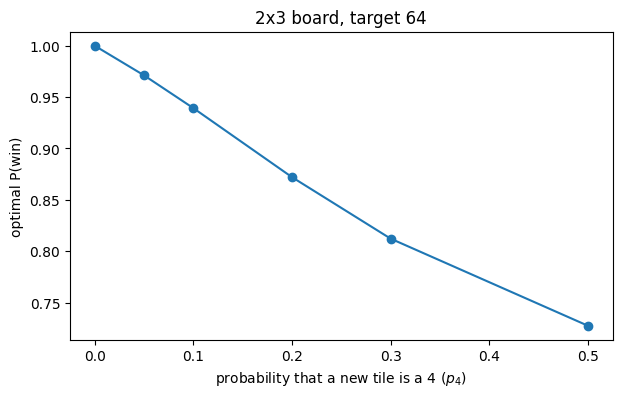

In [11]:
p4_values = [0.0, 0.05, 0.1, 0.2, 0.3, 0.5]
p_win = []
for p4 in p4_values:
    g = Game2048(2, 3, target=64, p4=p4)
    V_p4, _, _ = dp.solve_optimal(g)
    p_win.append(dp.start_value(g, V_p4))
    print(f'p4 = {p4:.2f}: optimal P(win) = {p_win[-1]:.4f}')

plt.plot(p4_values, p_win, marker='o')
plt.xlabel(r'probability that a new tile is a 4 ($p_4$)')
plt.ylabel('optimal P(win)')
plt.title('2x3 board, target 64')
plt.show()

## 8. Win probability or expected score?

With the merge points as stage reward (and no stop at the target) the same recursion maximises the expected score. Do the two optimal policies agree?

In [12]:
V_s, table_s, _ = dp.solve_optimal(game, objective='score')
score_policy = dp.table_policy(table_s)
p_win_score = dp.start_value(game, dp.evaluate_policy(game, score_policy, layers=layers))
agreement = dp.compare_with_heuristic(game, V, table, layers, score_policy)['share']
print(f'maximum expected score: {dp.start_value(game, V_s):.1f}')
print(f'P(win) of the score-optimal policy: {p_win_score:.4f} (win-optimal: {p_opt:.4f})')
print(f'the score-optimal move is win-optimal in {agreement:.1%} of the decisions')

maximum expected score: 480.3
P(win) of the score-optimal policy: 0.9387 (win-optimal: 0.9393)
the score-optimal move is win-optimal in 97.9% of the decisions


## 9. Watch the policies play

Each move takes two frames, as in the formulation: the afterstate (tiles slid and merged), then the board with the new random tile, which is outlined. The bar shows the optimal probability of winning from the current board: every random tile moves it, and you can watch how quickly the corner rule throws it away. Use the buttons under the board to play, pause or step through a game.

In [13]:
from IPython.display import HTML
from viz2048 import animate, play_episode

optimal = dp.table_policy(table)
HTML(animate(game, play_episode(game, optimal, seed=3, V=V)).to_jshtml())

The corner rule on the same seed. The bar is still the *optimal* win probability, i.e. what an optimal player could still achieve from that board.

In [14]:
HTML(animate(game, play_episode(game, dp.corner_policy, seed=3, V=V)).to_jshtml())

Even the optimal policy loses about 6% of the games: here is one of them.

In [15]:
lost_seed = next(s for s in range(10_000)
                 if play_episode(game, optimal, seed=s)[-1]['phase'] == 'lost')
print('seed', lost_seed)
HTML(animate(game, play_episode(game, optimal, seed=lost_seed, V=V)).to_jshtml())

seed 29


From a terminal, `python viz2048.py` opens a window where the game plays by itself (`python viz2048.py -h` lists the options, e.g. `--rows 4 --cols 4 --target 2048 --policy corner`). The same functions will show the RL agent playing in Part 2.

## 10. Discussion

**The heuristics are not just suboptimal, they are hopeless on small boards.** On the 2x3 board with target 64 the corner rule wins 0.07% of the games, the greedy rule 0.13% and random play 0.02%, while the optimal policy wins 93.9%. The exceptions ranked in section 6 show why: the corner rule is a fixed priority of moves, and on a board with six cells there is no room for a rigid order. In the most important exception (board `16 4 2 / 32 8 2`, visited in 24% of the optimal games) the corner rule plays `down`, which piles the two 2s and wastes a cell, while `up` merges them and keeps the big tiles together; the loss is 0.90 of win probability from a position that is otherwise won with certainty. The same pattern repeats: the optimal policy plays whatever move keeps the tiles that will merge next adjacent, even if it moves the large tiles away from the corner, and it plays the corner move in only half of its decisions. On bigger boards the gap narrows (corner 36% vs optimal 99.999% on 2x4/64, 43% vs 100% on 3x3/64), because there is more room to recover from a bad placement, but the rule of thumb remains far from optimal.

**Chance bounds what any player can achieve.** The optimal win probability falls from 1 at $p_4 = 0$ to 0.94 at the standard $p_4 = 0.1$ and 0.73 at $p_4 = 0.5$: the 4s are what makes the game lose, because they consume the small-tile budget needed to build the next large tile. On this board, about 6% of the games are lost by the best possible player, and no amount of skill recovers them. The Monte Carlo check (0.9395 +- 0.0033 over 20,000 games) confirms the exact value and shows that the games last 33 moves on average.

**Maximising the score is almost, but not exactly, the same as maximising the win probability.** The score-optimal policy wins 93.87% of the games against 93.93%, and agrees with the win-optimal move in 97.9% of the decisions. The disagreements are in positions where a merge gives points now but destroys the structure needed to create the target later. This matters for Part 2: the score is a dense reward (every merge pays), the win is a sparse one (only the final move pays), and the exact values tell us that learning with the score costs almost nothing in terms of winning.

**The state counts rule out the original game.** Doubling the target roughly doubles the states; adding a cell multiplies them by 30 to 180. The 3x3 board with target 64 has 4.8 million states and takes minutes and 1.5 GB in pure Python; the 4x4 board with target 2048 is bounded by $11^{16} \approx 4.6 \cdot 10^{16}$ states. Exact dynamic programming stops here, and the only way forward is to approximate the value function and to learn it from play, which is what Part 2 does, with the exact values of this notebook as the yardstick.

## Next: Part 2 (RL)

The RL part uses the same engine through `Env2048` (Gymnasium-style `reset`/`step`; `info['afterstate']` is the board after the slide/merge, for afterstate TD learning). The plan: validate the learning algorithms on the 2x3 board against the exact `V` computed here, then move to the 4x4 board with function approximation.

In [16]:
env = Env2048(Game2048(2, 3, target=64), reward='win', seed=0)
obs, info = env.reset()
print(env.game.render(obs))
print('legal actions:', info['legal_actions'])

. . .
4 . 2
legal actions: ['left', 'right', 'up']
